# 10.7 #5, 9, 10

5.

The same eight shoppers give three different clusterings, the raw counts let socks dominate, the standardized data weight both variables equally, and the dollar values let computers dominate. If we want each variable to contribute equally, we should normalize the weights first. Otherwise if we want to use the dollar values, we can leave them as they are.

9

Consider the USArrests data. We will now perform hierarchical clustering on the states.
(a) Using hierarchical clustering with complete linkage and
Euclidean distance, cluster the states.
(b) Cut the dendrogram at a height that results in three distinct
clusters. Which states belong to which clusters?
(c) Hierarchically cluster the states using complete linkage and Euclidean distance, after scaling the variables to have standard deviation one.
(d) What effect does scaling the variables have on the hierarchical
clustering obtained? In your opinion, should the variables be
scaled before the inter-observation dissimilarities are computed?
Provide a justification for your answer.

(a)

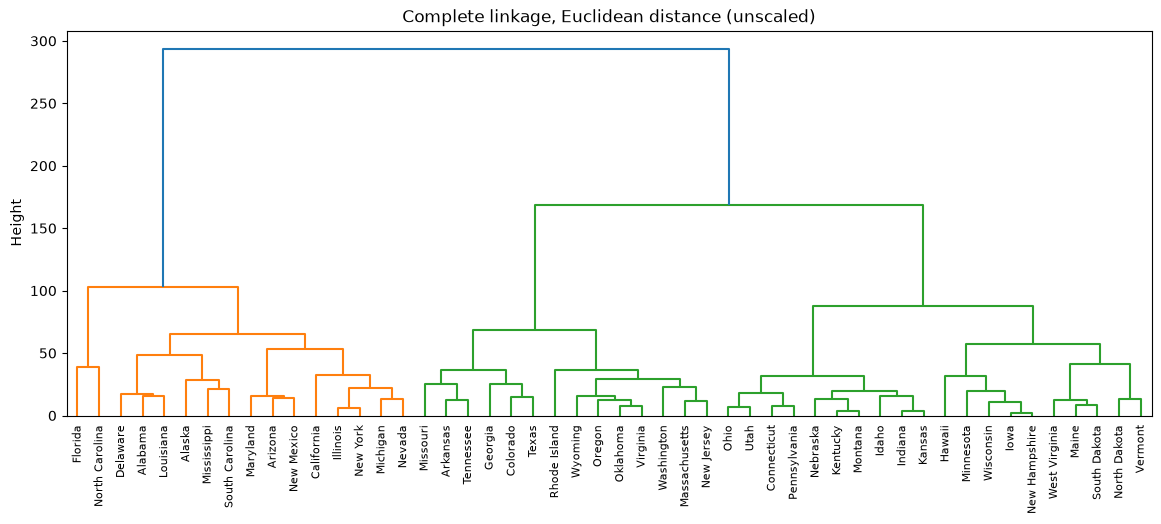

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

arrests = pd.read_csv('../../Data/ISLR_all_csv/USArrests.csv', index_col=0)

hc = linkage(arrests, method='complete', metric='euclidean')
plt.figure(figsize=(14, 5))
dendrogram(hc, labels=arrests.index, leaf_rotation=90)
plt.title('Complete linkage, Euclidean distance (unscaled)')
plt.ylabel('Height')
plt.show()

(b)

In [ ]:
cut = fcluster(hc, t=3, criterion='maxclust')
for k in (1, 2, 3):
    print(f'Cluster {k} ({(cut == k).sum()} states):', ', '.join(arrests.index[cut == k]), '\n')

Cluster 1 (16 states): Alabama, Alaska, Arizona, California, Delaware, Florida, Illinois, Louisiana, Maryland, Michigan, Mississippi, Nevada, New Mexico, New York, North Carolina, South Carolina 

Cluster 2 (14 states): Arkansas, Colorado, Georgia, Massachusetts, Missouri, New Jersey, Oklahoma, Oregon, Rhode Island, Tennessee, Texas, Virginia, Washington, Wyoming 

Cluster 3 (20 states): Connecticut, Hawaii, Idaho, Indiana, Iowa, Kansas, Kentucky, Maine, Minnesota, Montana, Nebraska, New Hampshire, North Dakota, Ohio, Pennsylvania, South Dakota, Utah, Vermont, West Virginia, Wisconsin 



(c)

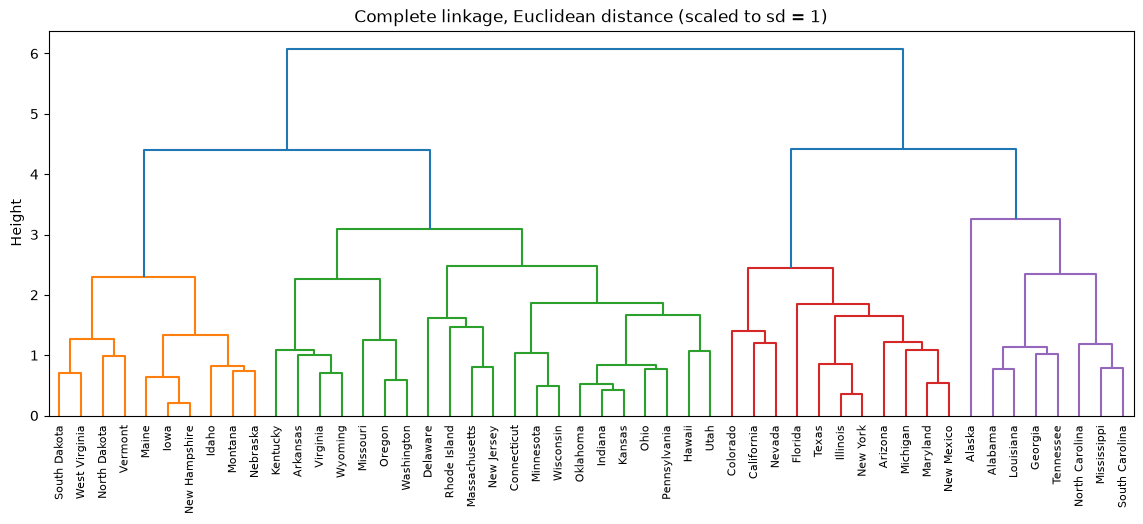

Cluster 1 (31 states): Arkansas, Connecticut, Delaware, Hawaii, Idaho, Indiana, Iowa, Kansas, Kentucky, Maine, Massachusetts, Minnesota, Missouri, Montana, Nebraska, New Hampshire, New Jersey, North Dakota, Ohio, Oklahoma, Oregon, Pennsylvania, Rhode Island, South Dakota, Utah, Vermont, Virginia, Washington, West Virginia, Wisconsin, Wyoming 

Cluster 2 (11 states): Arizona, California, Colorado, Florida, Illinois, Maryland, Michigan, Nevada, New Mexico, New York, Texas 

Cluster 3 (8 states): Alabama, Alaska, Georgia, Louisiana, Mississippi, North Carolina, South Carolina, Tennessee 



In [ ]:
scaled = arrests / arrests.std()

hc_s = linkage(scaled, method='complete', metric='euclidean')
plt.figure(figsize=(14, 5))
dendrogram(hc_s, labels=arrests.index, leaf_rotation=90)
plt.title('Complete linkage, Euclidean distance (scaled to sd = 1)')
plt.ylabel('Height')
plt.show()

cut_s = fcluster(hc_s, t=3, criterion='maxclust')
for k in (1, 2, 3):
    print(f'Cluster {k} ({(cut_s == k).sum()} states):', ', '.join(arrests.index[cut_s == k]), '\n')

(d)

In [ ]:
print(arrests.std().round(2))
print(pd.crosstab(cut, cut_s, rownames=['unscaled'], colnames=['scaled']))

Murder       4.36
Assault     83.34
UrbanPop    14.47
Rape         9.37
dtype: float64
scaled     1  2  3
unscaled          
1          1  9  6
2         10  2  2
3         20  0  0


Scaling changes the clustering a lot. The cluster sizes go from 16/14/20 (unscaled) to 31/11/8 (scaled), and the crosstab shows the groups don't line up. Without scaling, Assault has a standard deviation of about 83 versus about 4 for Murder, 15 for UrbanPop and 9 for Rape, so the distances (and the clusters) are driven almost entirely by Assault. Once every variable has standard deviation one, all four contribute.

I think the variables should be scaled. The four variables are in different units (arrests per 100,000 for three of them, a percentage of population for UrbanPop), so the size of the raw variances is arbitrary and shouldn't decide how much each variable matters. Scaling puts them on equal footing.

10

 In this problem, you will generate simulated data, and then perform
PCA and K-means clustering on the data.
(a) Generate a simulated data set with 20 observations in each of
three classes (i.e. 60 observations total), and 50 variables.
Hint: There are a number of functions in R that you can use to
generate data. One example is the rnorm() function; runif() is
another option. Be sure to add a mean shift to the observations
in each class so that there are three distinct classes.
(b) Perform PCA on the 60 observations and plot the first two principal component score vectors. Use a different color to indicate
the observations in each of the three classes. If the three classes
appear separated in this plot, then continue on to part (c). If
not, then return to part (a) and modify the simulation so that
there is greater separation between the three classes. Do not
continue to part (c) until the three classes show at least some
separation in the first two principal component score vectors.
(c) Perform K-means clustering of the observations with K = 3.
How well do the clusters that you obtained in K-means clustering compare to the true class labels?
Hint: You can use the table() function in R to compare the true
class labels to the class labels obtained by clustering. Be careful
how you interpret the results: K-means clustering will arbitrarily
number the clusters, so you cannot simply check whether the true
class labels and clustering labels are the same.
(d) Perform K-means clustering with K = 2. Describe your results.
(e) Now perform K-means clustering with K = 4, and describe your
results.
(f) Now perform K-means clustering with K = 3 on the first two
principal component score vectors, rather than on the raw data.
That is, perform K-means clustering on the 60 × 2 matrix of
which the first column is the first principal component score
vector, and the second column is the second principal component
score vector. Comment on the results.
(g) Using the scale() function, perform K-means clustering with
K = 3 on the data after scaling each variable to have standard
deviation one. How do these results compare to those obtained
in (b)? Explain.

(a)

In [ ]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

rng = np.random.default_rng(1)
n, p = 20, 50
shifts = [0, 2, 4]            # mean shift added to every variable of each class
X = np.vstack([rng.normal(shift, 1, size=(n, p)) for shift in shifts])
y = np.repeat([0, 1, 2], n)
X.shape

(60, 50)

(b)

Variance explained: [0.75  0.019]


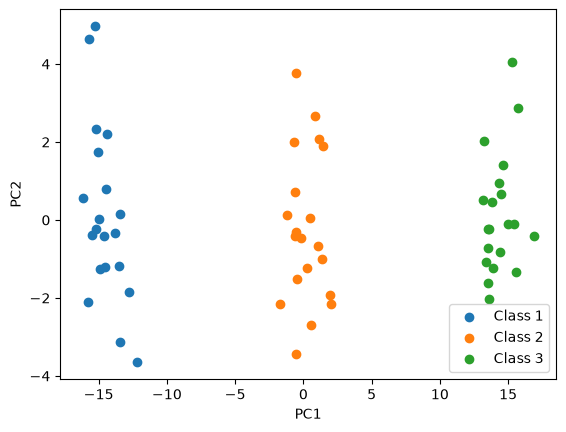

In [ ]:
pca = PCA(n_components=2)
Z = pca.fit_transform(X)
print('Variance explained:', pca.explained_variance_ratio_.round(3))

colors = ['tab:blue', 'tab:orange', 'tab:green']
for k in range(3):
    plt.scatter(Z[y == k, 0], Z[y == k, 1], c=colors[k], label=f'Class {k + 1}')
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.legend()
plt.show()

The three classes are clearly separated along PC1, so we can continue.

(c)

In [ ]:
km3 = KMeans(n_clusters=3, n_init=20, random_state=1).fit(X)
pd.crosstab(y + 1, km3.labels_, rownames=['true class'], colnames=['k-means cluster'])

k-means cluster,0,1,2
true class,,,
1,0,0,20
2,20,0,0
3,0,20,0


K-means with K = 3 recovers the true classes perfectly: each true class falls entirely in one cluster (the cluster numbers are arbitrary).

(d)

In [ ]:
km2 = KMeans(n_clusters=2, n_init=20, random_state=1).fit(X)
pd.crosstab(y + 1, km2.labels_, rownames=['true class'], colnames=['k-means cluster'])

k-means cluster,0,1
true class,,
1,0,20
2,20,0
3,20,0


With K = 2, classes 2 and 3 are merged into one cluster of 40 and class 1 is on its own. K-means has to combine two of the three groups, and here the means of classes 2 and 3 are the ones it grouped together.

(e)

In [ ]:
km4 = KMeans(n_clusters=4, n_init=20, random_state=1).fit(X)
pd.crosstab(y + 1, km4.labels_, rownames=['true class'], colnames=['k-means cluster'])

k-means cluster,0,1,2,3
true class,,,,
1,3,0,17,0
2,0,0,0,20
3,0,20,0,0


With K = 4, class 1 is split into two clusters (17 and 3 observations) while classes 2 and 3 stay intact. The extra cluster is an artificial split of what is really one group.

(f)

In [ ]:
km_pc = KMeans(n_clusters=3, n_init=20, random_state=1).fit(Z)
pd.crosstab(y + 1, km_pc.labels_, rownames=['true class'], colnames=['k-means cluster'])

k-means cluster,0,1,2
true class,,,
1,0,20,0
2,20,0,0
3,0,0,20


Clustering on the first two principal component scores gives the same perfect separation as clustering on all 50 variables. PC1 and PC2 hold the between-class structure, so little is lost by dropping the other components.

(g)

In [ ]:
Xs = StandardScaler().fit_transform(X)
km_s = KMeans(n_clusters=3, n_init=20, random_state=1).fit(Xs)
pd.crosstab(y + 1, km_s.labels_, rownames=['true class'], colnames=['k-means cluster'])

k-means cluster,0,1,2
true class,,,
1,0,0,20
2,20,0,0
3,0,20,0


Scaling each variable to standard deviation one gives the same clustering as the unscaled data. In this simulation every variable already has standard deviation about 1 (only the mean differs by class), so scaling barely changes the data, and the true classes are still recovered perfectly.